In [1]:
'''Compare and evaluate different hyperparameter tuning strategies
 (Grid Search, Random Search, Bayesian Optimization)
 on model performance, training time, and scalability for deployment.'''

'Compare and evaluate different hyperparameter tuning strategies\n (Grid Search, Random Search, Bayesian Optimization)\n on model performance, training time, and scalability for deployment.'

In [2]:
# import core libraries and timing utility
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [3]:
# import model selection and evaluation modules
from sklearn.model_selection import train_test_split, GridSearchCV, RandomizedSearchCV
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_squared_error, root_mean_squared_error, mean_absolute_error, r2_score
from skopt import BayesSearchCV

In [4]:
# load dataset from csv file
df = pd.read_csv('Adm.csv')

In [5]:
# inspect dataset shape and preview records
print('dataset shape:', df.shape)
print('first 3 samples:')
print(df.head(3))

dataset shape: (1000, 12)
first 3 samples:
   Serial No.  GRE Score  ...                             University_Name  region
0           1        337  ...    Indian Institute of Technology Kharagpur    East
1           2        324  ...  National Institute of Technology Karnataka   South
2           3        316  ...                          Gujarat University    West

[3 rows x 12 columns]


In [6]:
# verify absence of missing values
print('missing values check:')
print(df.isnull().sum())

missing values check:
Serial No.              0
GRE Score               0
TOEFL Score             0
University Rating       0
SOP                     0
LOR                     0
CGPA                    0
Research                0
Chance of Admit         0
Application_DateTime    0
University_Name         0
region                  0
dtype: int64


In [7]:
# define feature columns and target variable
features = ['GRE Score', 'TOEFL Score', 'University Rating', 'SOP', 'LOR', 'CGPA', 'Research']
target = 'Chance of Admit'

X = df[features]
y = df[target]

print('features:', features)
print('target:', target)

features: ['GRE Score', 'TOEFL Score', 'University Rating', 'SOP', 'LOR', 'CGPA', 'Research']
target: Chance of Admit


In [8]:
# partition data into training and test partitions
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

print('training samples:', len(X_train))
print('testing samples:', len(X_test))

training samples: 800
testing samples: 200


In [9]:
# initialize base machine learning model
base_model = RandomForestRegressor(random_state=42)

print('base random forest regressor initialized')

base random forest regressor initialized


In [10]:
# define search spaces for all three tuning strategies
grid_params = {
    'n_estimators': [25, 50, 75],
    'max_depth': [4, 8, 12],
    'min_samples_split': [2, 5],
    'min_samples_leaf': [1, 2]
}

random_params = {
    'n_estimators': [25, 50, 75, 100],
    'max_depth': [3, 5, 8, 10, 12, None],
    'min_samples_split': [2, 5, 8],
    'min_samples_leaf': [1, 2, 4]
}

bayes_params = {
    'n_estimators': (25, 100),
    'max_depth': (3, 12),
    'min_samples_split': (2, 8),
    'min_samples_leaf': (1, 4)
}

print('search configurations defined for grid search, random search, and bayesian optimization')

search configurations defined for grid search, random search, and bayesian optimization


In [11]:
# run and benchmark grid search strategy
start_time = time.time()
grid_search = GridSearchCV(base_model, grid_params, cv=3, scoring='r2', n_jobs=1)
grid_search.fit(X_train, y_train)
grid_time = time.time() - start_time

grid_model = grid_search.best_estimator_

# benchmark inference latency for deployment
inf_start = time.time()
grid_pred = grid_model.predict(X_test)
grid_inf_time = (time.time() - inf_start) * 1000

grid_r2 = r2_score(y_test, grid_pred)
grid_mse = mean_squared_error(y_test, grid_pred)
grid_rmse = root_mean_squared_error(y_test, grid_pred)
grid_mae = mean_absolute_error(y_test, grid_pred)

print('grid search time:', round(grid_time, 2), 's')
print('grid search best cv r2:', round(grid_search.best_score_, 4))
print('grid search test r2:', round(grid_r2, 4))
print('grid search best params:', grid_search.best_params_)

grid search time: 8.11 s
grid search best cv r2: 0.9086
grid search test r2: 0.9067
grid search best params: {'max_depth': 8, 'min_samples_leaf': 1, 'min_samples_split': 2, 'n_estimators': 75}


In [12]:
# run and benchmark random search strategy
start_time = time.time()
random_search = RandomizedSearchCV(base_model, random_params, n_iter=15, cv=3, scoring='r2', random_state=42, n_jobs=1)
random_search.fit(X_train, y_train)
random_time = time.time() - start_time

random_model = random_search.best_estimator_

# benchmark inference latency for deployment
inf_start = time.time()
random_pred = random_model.predict(X_test)
random_inf_time = (time.time() - inf_start) * 1000

random_r2 = r2_score(y_test, random_pred)
random_mse = mean_squared_error(y_test, random_pred)
random_rmse = root_mean_squared_error(y_test, random_pred)
random_mae = mean_absolute_error(y_test, random_pred)

print('random search time:', round(random_time, 2), 's')
print('random search best cv r2:', round(random_search.best_score_, 4))
print('random search test r2:', round(random_r2, 4))
print('random search best params:', random_search.best_params_)

random search time: 4.76 s
random search best cv r2: 0.9093
random search test r2: 0.9083
random search best params: {'n_estimators': 100, 'min_samples_split': 2, 'min_samples_leaf': 1, 'max_depth': 10}


In [13]:
# run and benchmark bayesian optimization strategy
start_time = time.time()
bayes_search = BayesSearchCV(base_model, bayes_params, n_iter=15, cv=3, scoring='r2', random_state=42, n_jobs=1)
bayes_search.fit(X_train, y_train)
bayes_time = time.time() - start_time

bayes_model = bayes_search.best_estimator_

# benchmark inference latency for deployment
inf_start = time.time()
bayes_pred = bayes_model.predict(X_test)
bayes_inf_time = (time.time() - inf_start) * 1000

bayes_r2 = r2_score(y_test, bayes_pred)
bayes_mse = mean_squared_error(y_test, bayes_pred)
bayes_rmse = root_mean_squared_error(y_test, bayes_pred)
bayes_mae = mean_absolute_error(y_test, bayes_pred)

print('bayesian optimization time:', round(bayes_time, 2), 's')
print('bayesian optimization best cv r2:', round(bayes_search.best_score_, 4))
print('bayesian optimization test r2:', round(bayes_r2, 4))
print('bayesian optimization best params:', dict(bayes_search.best_params_))

bayesian optimization time: 7.48 s
bayesian optimization best cv r2: 0.909
bayesian optimization test r2: 0.9088
bayesian optimization best params: {'max_depth': 12, 'min_samples_leaf': 1, 'min_samples_split': 2, 'n_estimators': 100}


In [14]:
# build comprehensive comparison dataframe
comparison_df = pd.DataFrame({
    'strategy': ['grid search', 'random search', 'bayesian optimization'],
    'best_cv_r2': [grid_search.best_score_, random_search.best_score_, bayes_search.best_score_],
    'test_r2': [grid_r2, random_r2, bayes_r2],
    'test_rmse': [grid_rmse, random_rmse, bayes_rmse],
    'test_mae': [grid_mae, random_mae, bayes_mae],
    'training_time_s': [grid_time, random_time, bayes_time],
    'candidates_tested': [len(grid_search.cv_results_['params']), 15, 15],
    'inference_latency_ms': [grid_inf_time, random_inf_time, bayes_inf_time]
})

print('comprehensive benchmark comparison:')
print(comparison_df.round(4).to_string(index=False))

comprehensive benchmark comparison:
             strategy  best_cv_r2  test_r2  test_rmse  test_mae  training_time_s  candidates_tested  inference_latency_ms
          grid search      0.9086   0.9067     0.0309    0.0237           8.1099                 36                4.6000
        random search      0.9093   0.9083     0.0306    0.0235           4.7650                 15                6.4473
bayesian optimization      0.9090   0.9088     0.0306    0.0234           7.4796                 15                8.7357


In [15]:
# display detailed scalability and efficiency analysis
efficiency_df = pd.DataFrame({
    'strategy': comparison_df['strategy'],
    'time_per_candidate_s': comparison_df['training_time_s'] / comparison_df['candidates_tested'],
    'inference_latency_ms': comparison_df['inference_latency_ms'],
    'relative_speedup': comparison_df['training_time_s'].max() / comparison_df['training_time_s']
})

print('scalability and deployment efficiency analysis:')
print(efficiency_df.round(4).to_string(index=False))

scalability and deployment efficiency analysis:
             strategy  time_per_candidate_s  inference_latency_ms  relative_speedup
          grid search                0.2253                4.6000            1.0000
        random search                0.3177                6.4473            1.7020
bayesian optimization                0.4986                8.7357            1.0843


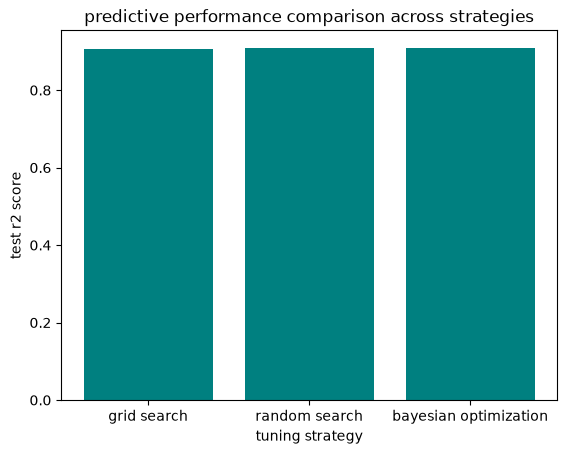

In [16]:
# plot predictive performance comparison across strategies
plt.bar(comparison_df['strategy'], comparison_df['test_r2'], color='teal')
plt.title('predictive performance comparison across strategies')
plt.xlabel('tuning strategy')
plt.ylabel('test r2 score')
plt.show()

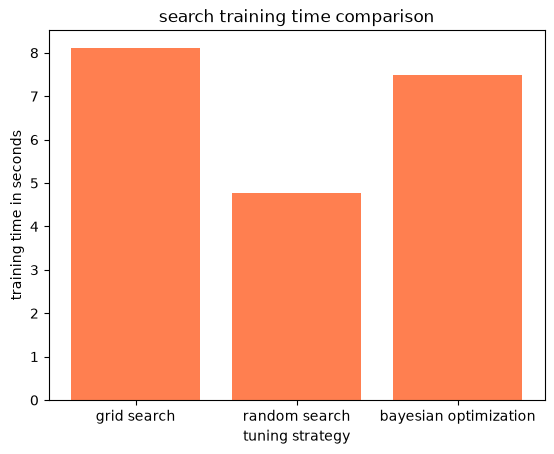

In [17]:
# plot search training time comparison across strategies
plt.bar(comparison_df['strategy'], comparison_df['training_time_s'], color='coral')
plt.title('search training time comparison')
plt.xlabel('tuning strategy')
plt.ylabel('training time in seconds')
plt.show()

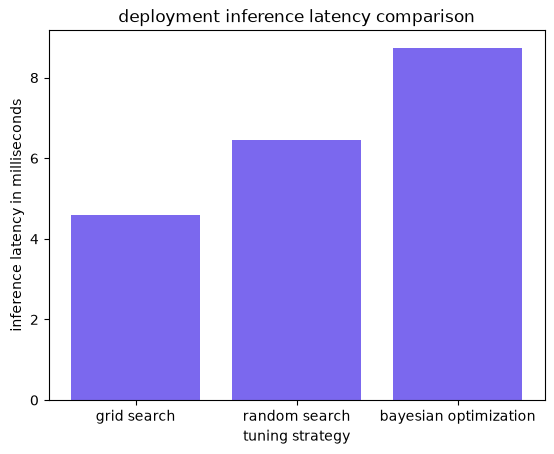

In [18]:
# plot deployment inference latency comparison across strategies
plt.bar(comparison_df['strategy'], comparison_df['inference_latency_ms'], color='mediumslateblue')
plt.title('deployment inference latency comparison')
plt.xlabel('tuning strategy')
plt.ylabel('inference latency in milliseconds')
plt.show()